# Olist E-Commerce Analysis
Analysis of ~99K Brazilian marketplace orders to answer three business questions:
1. How many orders fail, and how much revenue does that affect?
2. Do late deliveries get lower review scores?
3. Which product categories drive revenue?
Data: Olist Brazilian E-Commerce dataset (Kaggle).

## Q1: Failed orders
1,234 of 99,441 orders (1.2%) were canceled or unavailable. Their items account for about R$97K of R$13.6M in item revenue (0.72%). This is a lower bound, because most unavailable orders have no items in the data.

## Q3: Top categories
health_beauty, watches_gifts and bed_bath_table lead on revenue. watches_gifts earns revenue from fewer, pricier items (~R$201 each), and 5 of its 101 sellers hold about 63% of its revenue.

In [1]:
import pandas as pd
orders = pd.read_csv("../data/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [2]:
import pandas as pd
import glob, os

tables = {}
for path in glob.glob("../data/*.csv"):
    name = os.path.basename(path).replace("olist_", "").replace("_dataset.csv", "")
    tables[name] = pd.read_csv(path)

for name, df in tables.items():
    print(name, df.shape)


customers (99441, 5)
geolocation (1000163, 5)
orders (99441, 8)
order_items (112650, 7)
order_payments (103886, 5)
order_reviews (99224, 7)
products (32951, 9)
sellers (3095, 4)
product_category_name_translation.csv (71, 2)


In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [5]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
customers = tables["customers"]
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [8]:
customers.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [9]:
orders[orders["order_delivered_customer_date"].isna()]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [10]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [11]:
failed = orders["order_status"].isin(["canceled", "unavailable"])
failed.mean() * 100

np.float64(1.2409368369183738)

In [12]:
orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [13]:
items = tables["order_items"]
products = tables["products"]
trans = tables["product_category_name_translation.csv"]

df = items.merge(products[["product_id", "product_category_name"]],
                 on="product_id", how="left")
df = df.merge(trans, on="product_category_name", how="left")

print(items.shape, df.shape)


(112650, 7) (112650, 9)


In [14]:
df["product_category_name_english"].isna().sum()

np.int64(1627)

In [15]:
df.groupby("product_category_name_english")["price"].sum().sort_values(ascending=False).head(10)

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64

In [16]:
df.shape

(112650, 9)

In [17]:
items.shape

(112650, 7)

In [18]:
cat = df.groupby("product_category_name_english").agg(revenue=("price", "sum"), items_sold=("price", "count"), avg_price=("price", "mean"),) .sort_values("revenue", ascending=False)
cat.head(10)

,revenue,items_sold,avg_price
product_category_name_english,,,
health_beauty,1258681.34,9670,130.163531
watches_gifts,1205005.68,5991,201.135984
bed_bath_table,1036988.68,11115,93.296327
sports_leisure,988048.97,8641,114.344285
computers_accessories,911954.32,7827,116.513903
furniture_decor,729762.49,8334,87.564494
cool_stuff,635290.85,3796,167.357969
housewares,632248.66,6964,90.788148
auto,592720.11,4235,139.957523


In [19]:
df = df.merge(orders[["order_id", "order_status"]], on="order_id", how="left")
print(len(df))

112650


In [20]:
failed = df["order_status"].isin(["canceled", "unavailable"])
lost = df[failed]["price"].sum()
total = df["price"].sum()
print(lost, total, lost / total * 100)

97242.95999999999 13591643.700000003 0.7154613683700373


In [21]:
print(failed.sum(), len(df))
print(failed.mean() * 100)
df["order_status"].value_counts()

549 112650
0.48735019973368837


order_status
delivered      110197
shipped          1185
canceled          542
invoiced          359
processing        357
unavailable         7
approved            3
Name: count, dtype: int64

In [22]:
df[failed]["price"]

84         39.90
270        27.90
422       154.90
543       109.90
558         5.53
           ...  
110535      9.90
111019     28.90
111703     57.99
112073     39.90
112082    189.00
Name: price, Length: 549, dtype: float64

In [23]:
sellers = df.groupby("product_category_name_english")["seller_id"].nunique()
sellers[["watches_gifts", "bed_bath_table"]]

product_category_name_english
watches_gifts     101
bed_bath_table    196
Name: seller_id, dtype: int64

In [24]:
df[~failed].groupby("product_category_name_english")["price"].sum().sort_values(ascending=False).head(10)

product_category_name_english
health_beauty            1255695.13
watches_gifts            1198185.21
bed_bath_table           1035964.06
sports_leisure            979740.92
computers_accessories     904322.02
furniture_decor           727465.05
housewares                626825.80
cool_stuff                620770.49
auto                      586585.73
garden_tools              481009.94
Name: price, dtype: float64

In [25]:
w = df[df["product_category_name_english"] == "watches_gifts"]
w.groupby("seller_id")["price"].sum().sort_values(ascending=False).head(5)

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    201071.73
fa1c13f2614d7b5c4749cbc52fecda94    192092.74
7e93a43ef30c4f03f38b393420bc753a    169768.06
6560211a19b47992c3666cc44a7e94c0    100913.00
7d13fca15225358621be4086e1eb0964     90112.07
Name: price, dtype: float64

In [26]:
top5 = w.groupby("seller_id")["price"].sum().sort_values(ascending=False).head(5)
top5.sum() / w["price"].sum() * 100

np.float64(62.568800505571076)

In [27]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders["order_delivered_customer_date"].dtype

dtype('<M8[ns]')

In [28]:
reviews = tables["order_reviews"]
print(reviews.shape, reviews["order_id"].nunique())

delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()
delivered["days_late"] = (delivered["order_delivered_customer_date"]
                          - delivered["order_estimated_delivery_date"]).dt.days
delivered["is_late"] = delivered["days_late"] > 0
delivered["is_late"].mean() * 100

(99224, 7) 98673


np.float64(6.7730900798175595)

In [29]:
rev = reviews.groupby("order_id")["review_score"].mean().reset_index()

d = delivered.merge(rev, on="order_id", how="left")
print(len(delivered), len(d))   # must match

d.groupby("is_late")["review_score"].agg(["mean", "count"])

96470 96470


,mean,count
is_late,,
False,4.290589,89443
True,2.271823,6381


In [30]:
d["late_bucket"] = pd.cut(d["days_late"], bins=[-1000, 0, 3, 7, 14, 1000],
                          labels=["on time", "1-3", "4-7", "8-14", "15+"])
d.groupby("late_bucket", observed=True)["review_score"].agg(["mean", "count"])

,mean,count
late_bucket,,
on time,4.290589,89443
1-3,3.291037,1852
4-7,2.105549,1748
8-14,1.671508,1446
15+,1.725843,1335


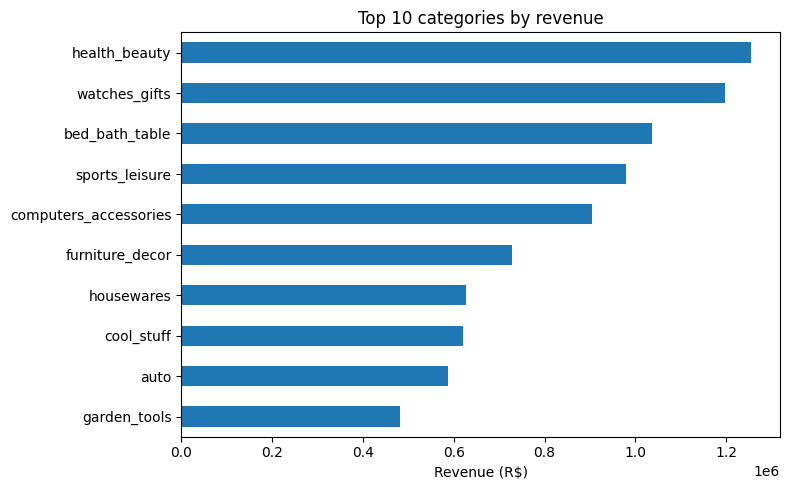

In [31]:
import matplotlib.pyplot as plt

top10 = (df[~failed]
         .groupby("product_category_name_english")["price"]
         .sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh")
plt.title("Top 10 categories by revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/top_categories.png", dpi=150)
plt.show()

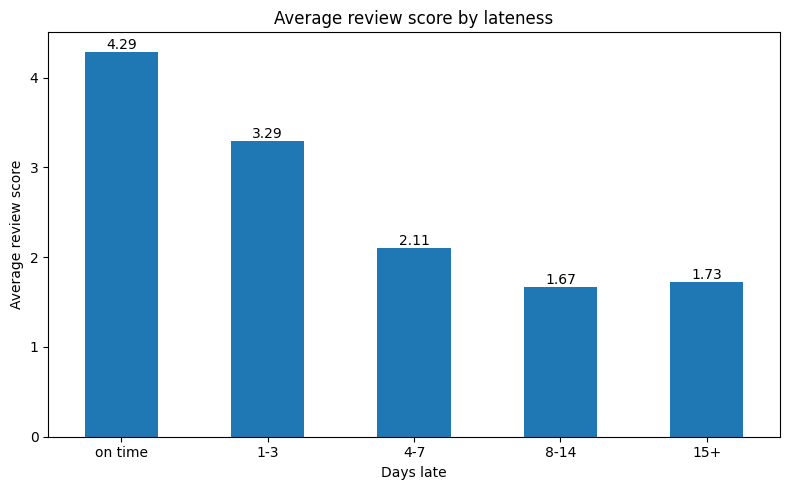

In [34]:
import matplotlib.pyplot as plt

average_review = d.groupby("late_bucket", observed=True)["review_score"].mean()

plt.figure(figsize=(8, 5))
average_review.plot(kind="bar")
plt.title("Average review score by lateness")
plt.xlabel("Days late")
plt.ylabel("Average review score")
plt.xticks(rotation=0)
plt.bar_label(plt.gca().containers[0], fmt="%.2f")
plt.tight_layout()
plt.savefig("../images/average_review_by_late_bucket.png", dpi=150)
plt.show()